# **1. Importing Necessary Libraries.**

In [1]:
#=======================================================
# Core libraries
# ======================================================
import pandas as pd
import numpy as np

# =====================================================
# Visualization Libraries.
# =====================================================
import matplotlib.pyplot as plt
import seaborn as sns

# =======================================================
# Preprocessing libraries
# =======================================================
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# =======================================================
# Model libraries
# =======================================================
from sklearn.model_selection import train_test_split,cross_val_score, cross_validate, cross_val_predict,StratifiedKFold
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix
)

# ========================================================
# Settings
# ========================================================
# ---- Plotting settings ----
sns.set_style("whitegrid")          # clean background with light gridlines
sns.set_context("notebook")         # font/element scaling (try "talk" for bigger presentation-style plots)
sns.set_palette("viridis")          # colorblind-friendly, works well for both categorical and sequential data

plt.rcParams["figure.figsize"] = (10, 6)   # default figure size
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["font.size"] = 11

# ---- Pandas display settings ----
pd.set_option("display.max_columns", None)   # show all columns, no truncation
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)  # 2 decimal places instead of scientific notation

# ---- Warnings ----
import warnings
warnings.filterwarnings("ignore")   # optional — silences sklearn/pandas deprecation noise during EDA

print('All the libraries imported sucessfully...')

All the libraries imported sucessfully...


# **2. Loading And Initial Inspection of the Data.**

In [2]:
# ================================================
# loading And inspecting the data.
# ================================================

#------------- Loading csv file----------
data = pd.read_csv('/kaggle/input/datasets/uditjain13/heart-disease-risk-2026/heart_disease_risk_2026.csv')

#------------ Printing the first 5 rows of the data ------
data.head()

,patient_id,age,sex,resting_bp_systolic,resting_bp_diastolic,cholesterol_total,hdl,ldl,triglycerides,fasting_blood_sugar,hba1c,bmi,resting_heart_rate,max_heart_rate_achieved,chest_pain_type,exercise_induced_angina,st_depression,family_history,smoker_status,alcohol_units_per_week,exercise_minutes_per_week,sleep_hours,stress_score,wearable_owner,daily_steps,diet_quality_score,has_heart_disease
0,1,44,Male,117,74,193,57,106,119,112,5.20,26.50,74,165,Asymptomatic,False,0.30,False,Never,2.90,86,5.40,19.80,True,7731,62.90,0
1,2,57,Male,139,94,185,69,110,35,114,5.90,20.80,63,150,Non-Anginal Pain,False,2.10,False,Never,3.00,132,4.30,45.80,True,2629,74.60,1
2,3,29,Male,128,78,197,52,108,157,95,5.50,24.50,81,210,Asymptomatic,False,0.80,False,Current,3.50,128,5.10,17.70,True,9290,65.70,0
3,4,72,Male,132,86,197,59,104,143,92,4.80,27.30,93,137,Asymptomatic,False,2.10,False,Never,2.70,18,6.80,63.60,True,7373,48.50,1
4,5,62,Female,116,75,154,65,75,104,135,6.20,26.00,86,181,Atypical Angina,True,1.30,True,Former,3.30,24,8.20,58.70,False,6331,47.30,1


In [3]:
# ==================================================
# Deep inspection
# ==================================================
#--------------Shape of the data--------------
print(f'Shape Of Data: {data.shape}.')

Shape Of Data: (9000, 27).


In [4]:
#---------------Checking for missing Values-------------
print('=======================Missing Values========================')
data.isna().sum()


=======================Missing Values========================


patient_id                   0
age                          0
sex                          0
resting_bp_systolic          0
resting_bp_diastolic         0
cholesterol_total            0
hdl                          0
ldl                          0
triglycerides                0
fasting_blood_sugar          0
hba1c                        0
bmi                          0
resting_heart_rate           0
max_heart_rate_achieved      0
chest_pain_type              0
exercise_induced_angina      0
st_depression                0
family_history               0
smoker_status                0
alcohol_units_per_week       0
exercise_minutes_per_week    0
sleep_hours                  0
stress_score                 0
wearable_owner               0
daily_steps                  0
diet_quality_score           0
has_heart_disease            0
dtype: int64

In [5]:
# ------------------Checking on duplicates in the data ----------
print(f'Duplicates Sum: {data.duplicated().sum()}')

Duplicates Sum: 0


In [6]:
# ----------------------------Deep audit of the datset------------------
def audit_data():
    return pd.DataFrame({
        'Missing':data.isna().sum(),
        'Missing%':(data.isna().sum()/len(data)),
        'DataType':data.dtypes,
        'Unique':data.nunique(),
        'Unique%':(data.nunique()/len(data)),
        'Samples':(data.loc[0])
    })

audit_data()

,Missing,Missing%,DataType,Unique,Unique%,Samples
patient_id,0,0.00,int64,9000,1.00,1
age,0,0.00,int64,73,0.01,44
sex,0,0.00,object,2,0.00,Male
resting_bp_systolic,0,0.00,int64,93,0.01,117
resting_bp_diastolic,0,0.00,int64,71,0.01,74
cholesterol_total,0,0.00,int64,200,0.02,193
hdl,0,0.00,int64,81,0.01,57
ldl,0,0.00,int64,163,0.02,106
triglycerides,0,0.00,int64,281,0.03,119
fasting_blood_sugar,0,0.00,int64,136,0.02,112


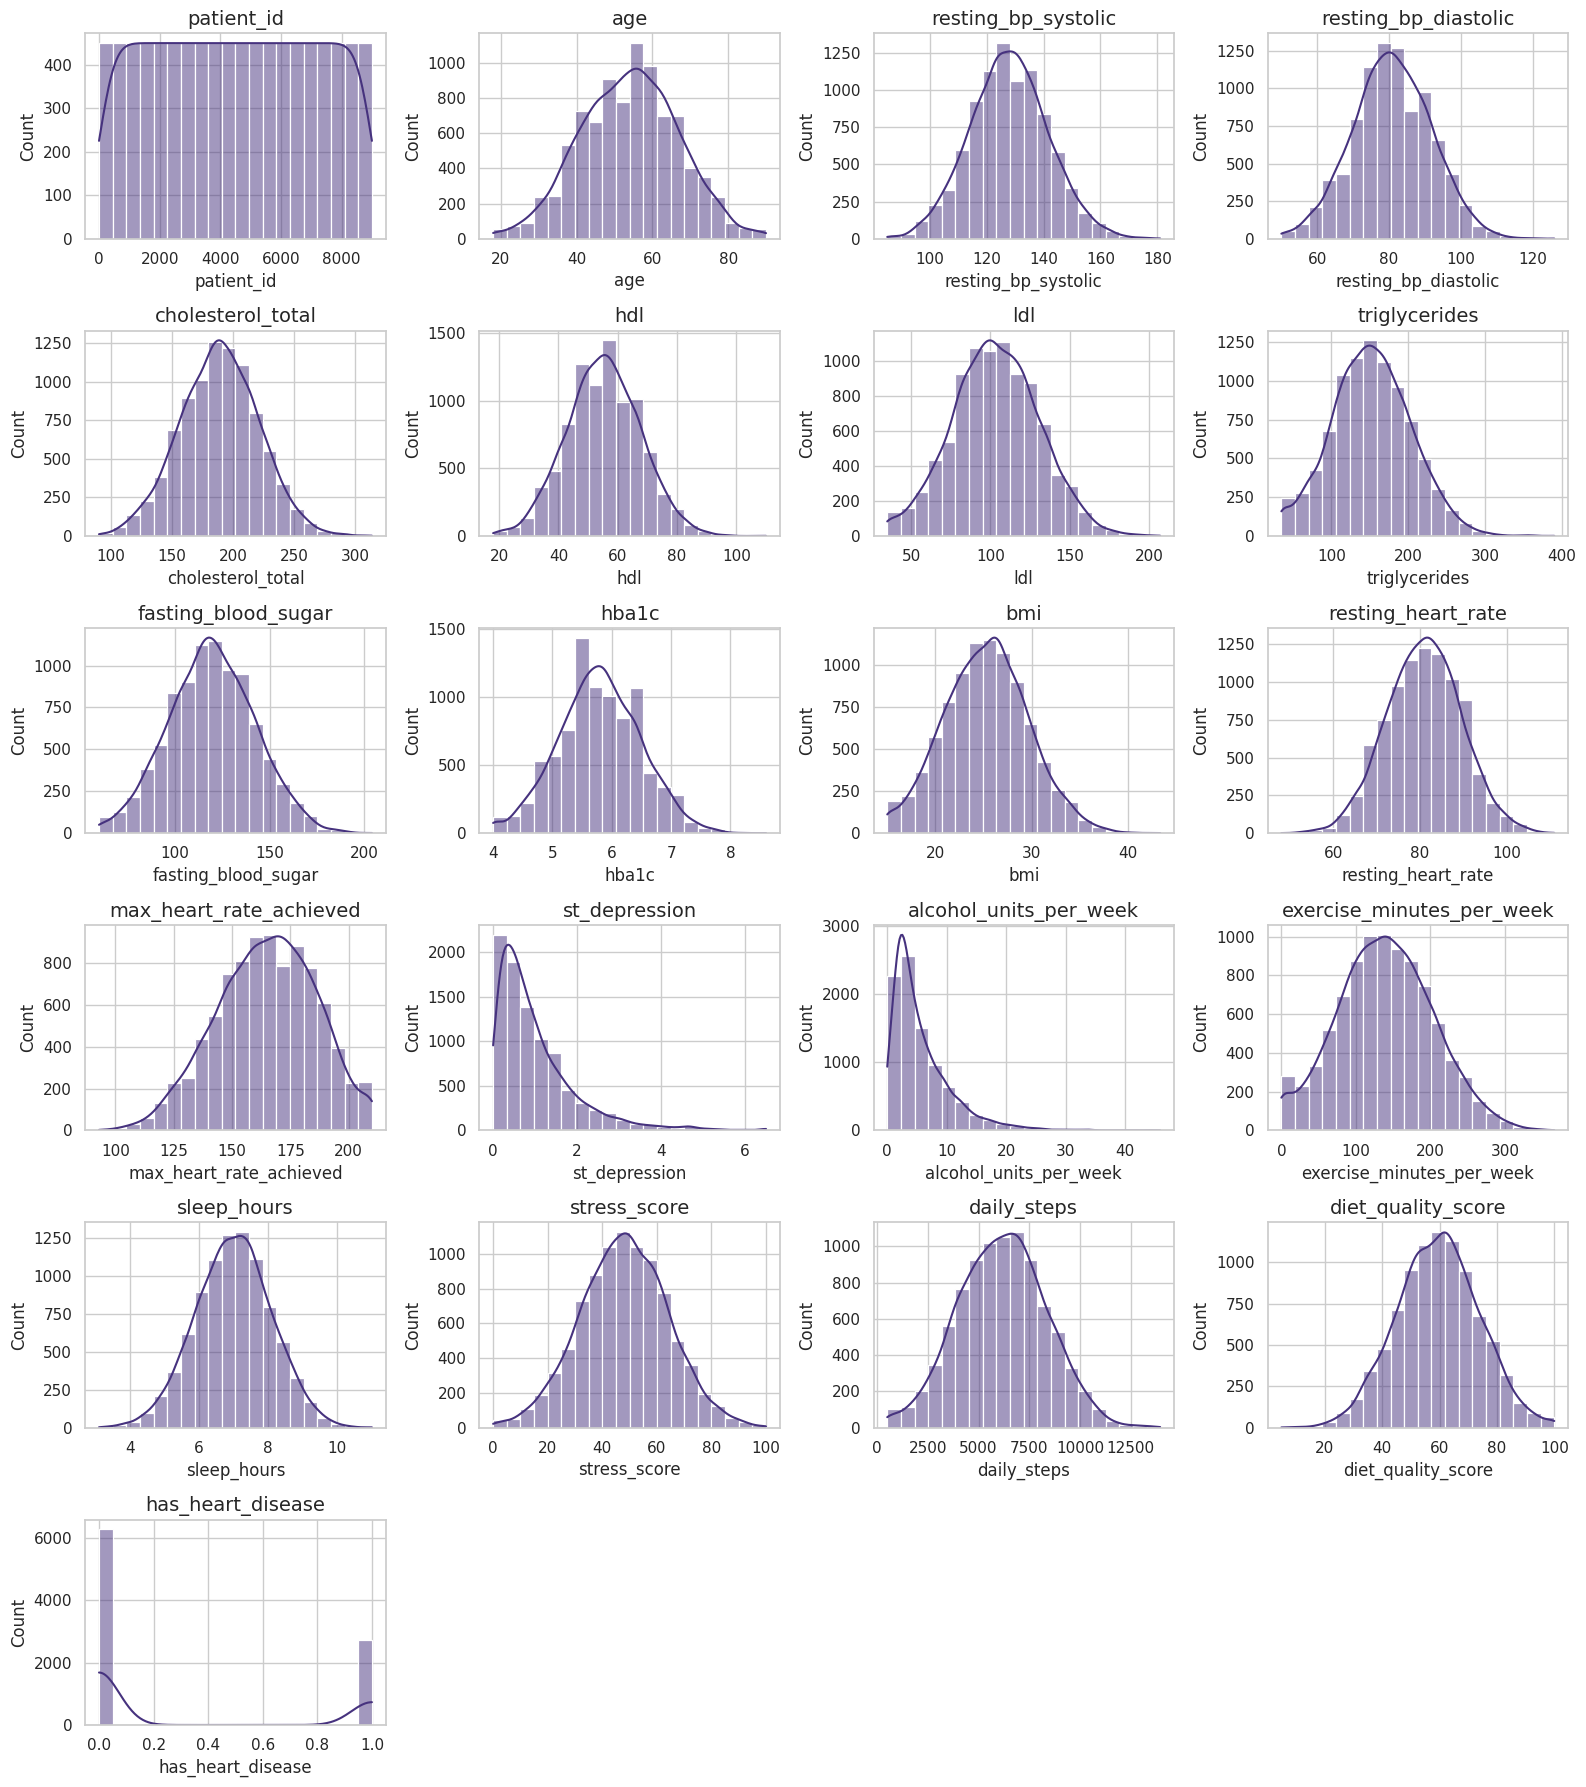

In [7]:
# ================================================================
# Checking the Distribution of numetic data
# ================================================================
num_col = data.select_dtypes(include='number').columns
n_cols = 4

n_rows = -(-len(num_col) // n_cols)
fig, axis = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*3))
axis = axis.flatten()

for i, col in enumerate(num_col):
    sns.histplot(data[col],bins=20,kde=True,ax=axis[i])
    axis[i].set_title(col)

for j in range(i + 1, len(axis)):
    axis[j].axis('off')

plt.tight_layout()
plt.show()

**Distribution Analysis**

---

The distributions of most continuous numerical variables are approximately symmetric and broadly bell-shaped, suggesting that extreme skewness is not a major issue across the dataset. However, st_depression and alcohol_units_per_week exhibit pronounced right-skewness, with observations concentrated at lower values and extended upper tails. max_heart_rate_achieved shows a mild left-skewed distribution. These skewed variables require further investigation to determine whether their extreme values represent genuine observations or potential outliers.

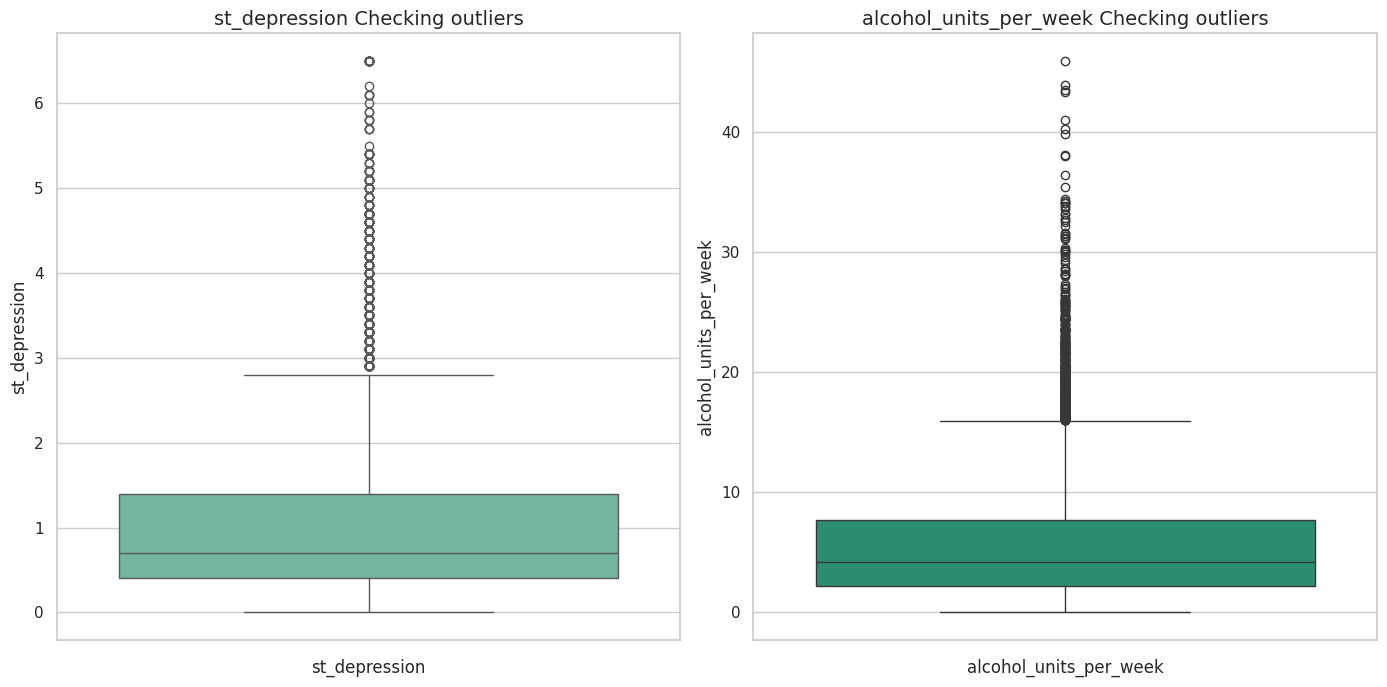

===================Skewness=============================================
Skewness for alcohol_units_per_week:2.0272341648523686
Skewness for st_depression:2.040910732021877


In [8]:
# ==============================================================
# Plotting a Box Plot to check if the data has Outliers or Not
# ==============================================================
fig, axis = plt.subplots(1,2,figsize=(14,7))
sns.boxplot(data = data, y = 'st_depression',palette="Set2",ax = axis[0])
axis[0].set_title('st_depression Checking outliers')
axis[0].set_xlabel('st_depression')

sns.boxplot(data = data, y= 'alcohol_units_per_week',palette="Dark2",ax = axis[1])
axis[1].set_title('alcohol_units_per_week Checking outliers')
axis[1].set_xlabel('alcohol_units_per_week')

plt.tight_layout()
plt.show()

# ------------------Checking The Skewness ------------------------
print('===================Skewness=============================================')
print(f'Skewness for alcohol_units_per_week:{data['alcohol_units_per_week'].skew()}')
print(f'Skewness for st_depression:{data['st_depression'].skew()}')

In [9]:
# ===========================================================
# Statistical methods to check for skewness
# ===========================================================

Q1 = data['st_depression'].quantile(0.25)
Q3 = data['st_depression'].quantile(0.75)
 
IQR = Q3 - Q1
upper_bound = Q3 + IQR * 1.5
outliers = data[data['st_depression'] > upper_bound]
 
print(f"Upper Bound: {upper_bound:.2f}")
print(f"Number of Outliers: {len(outliers)}, {len(outliers)/len(data) * 100:.2f}% of the data.")

Upper Bound: 2.90
Number of Outliers: 485, 5.39% of the data.


`st_depression` has an upper outlier boundary of 2.90, with only one observation (0.01%) exceeding this threshold. The extremely small proportion suggests that outliers are not a significant concern for this variable.

In [10]:

Q1 = data['alcohol_units_per_week'].quantile(0.25)
Q3 = data['alcohol_units_per_week'].quantile(0.75)
 
IQR = Q3 - Q1
upper_bound = Q3 + IQR * 1.5
outliers = data[data['alcohol_units_per_week'] > upper_bound]
 
print(f"Upper Bound: {upper_bound:.2f}")
print(f"Number of Outliers: {len(outliers)}, {len(outliers)/len(data) * 100:.2f}% of the data.")
 

Upper Bound: 15.95
Number of Outliers: 431, 4.79% of the data.


`alcohol_units_per_week` has an upper outlier boundary of 2.90, with only one observation (0.01%) exceeding this threshold. The extremely small proportion suggests that outliers are not a significant concern for this variable.

# **3. Exploratory Data Analysis.**

In [11]:
cat_col = data.select_dtypes(include='object').columns
print(cat_col)
print(num_col)

Index(['sex', 'chest_pain_type', 'smoker_status'], dtype='object')
Index(['patient_id', 'age', 'resting_bp_systolic', 'resting_bp_diastolic',
       'cholesterol_total', 'hdl', 'ldl', 'triglycerides',
       'fasting_blood_sugar', 'hba1c', 'bmi', 'resting_heart_rate',
       'max_heart_rate_achieved', 'st_depression', 'alcohol_units_per_week',
       'exercise_minutes_per_week', 'sleep_hours', 'stress_score',
       'daily_steps', 'diet_quality_score', 'has_heart_disease'],
      dtype='object')


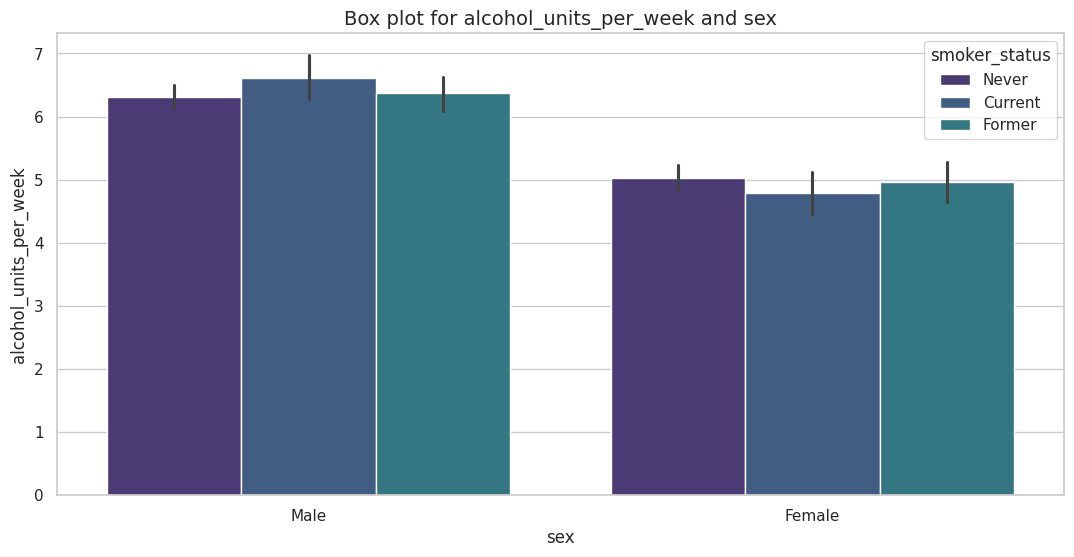

In [12]:
# ==================================================================
# Plotting a barplot for sex and alcohol_units_per_week
# ==================================================================
plt.figure(figsize = (13,6))
sns.barplot(data=data, y = 'alcohol_units_per_week',x = 'sex',hue='smoker_status')
plt.title('Box plot for alcohol_units_per_week and sex')
plt.show()

---

Alcohol consumption varies by both sex and smoking status. Across all smoking-status categories, males have higher average weekly alcohol consumption than females. Among males, current smokers have the highest average alcohol consumption, followed by former smokers and never smokers. Among females, never smokers have the highest average, while current smokers have the lowest. Overall, the results suggest that males in this dataset consume more alcohol per week than females, and the relationship between smoking status and alcohol consumption differs by sex.

---

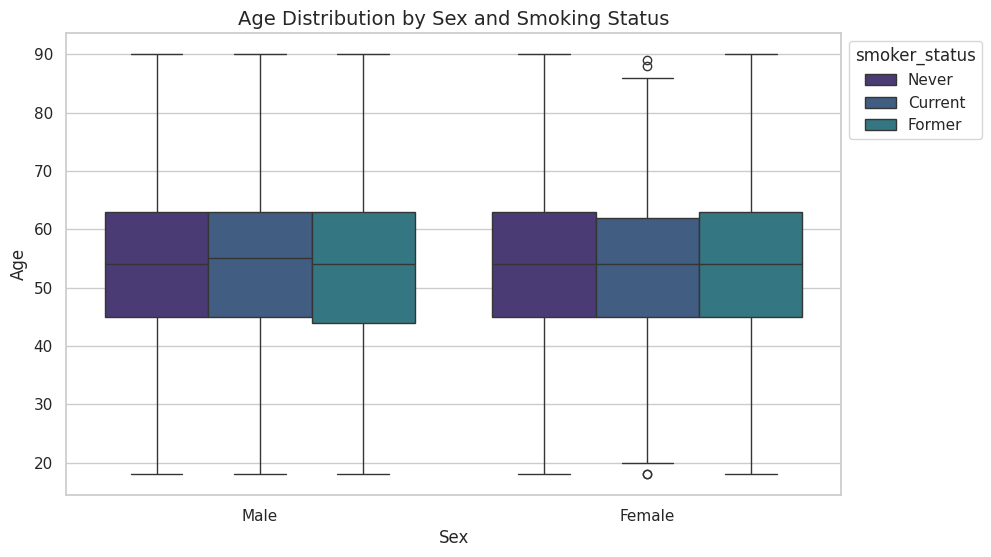

In [13]:
# =========================================================
# Grouping sex and smokers by age and alcohol units per weak
#===========================================================
plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=data,x='sex',y='age',hue='smoker_status')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title('Age Distribution by Sex and Smoking Status')
plt.xlabel('Sex')
plt.ylabel('Age')
plt.show()

In [14]:
# =====================================================================
# Creating age groups for checking age distribution with sex
# ====================================================================
data['age_group'] = pd.cut(
    data['age'],
    bins=[18, 30, 40, 50, 60, 70, 80, 100],
    labels=['18-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81+']
)
age_smoking = (
    data.groupby(['sex', 'smoker_status', 'age_group'], observed=True)
        .size()
        .reset_index(name='count')
)

age_smoking

,sex,smoker_status,age_group,count
0,Female,Current,18-30,23
1,Female,Current,31-40,88
2,Female,Current,41-50,176
3,Female,Current,51-60,231
4,Female,Current,61-70,152
5,Female,Current,71-80,53
6,Female,Current,81+,13
7,Female,Former,18-30,32
8,Female,Former,31-40,124
9,Female,Former,41-50,302


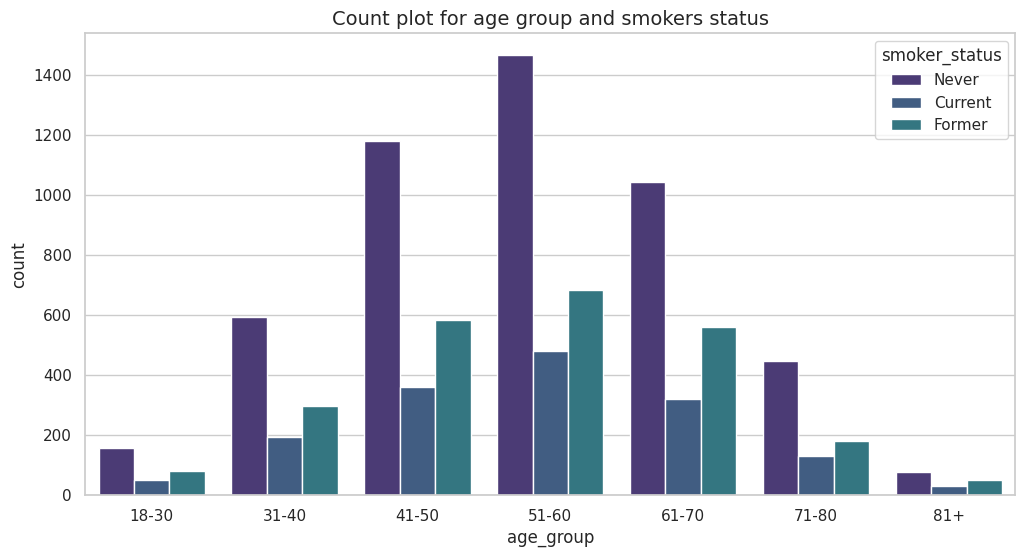

In [15]:
# =================================================================
# Count plot for Age and sex and smoking status
# =================================================================
plt.figure(figsize=(12, 6))
sns.countplot(data=data,x='age_group',hue='smoker_status')
plt.title('Count plot for age group and smokers status')
plt.show()

======================================== Count plots for Male class and Female class ========================================


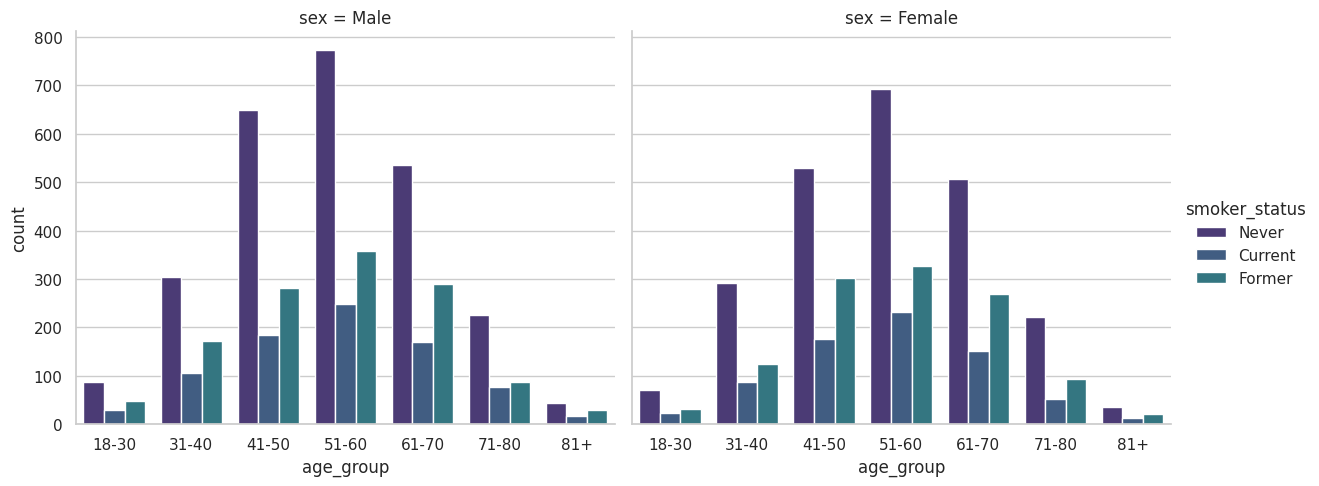

In [16]:
# ==================================================================
# Creating count plot for separet classes of gender
# ==================================================================
print('='*80)
print('='*40,'Count plots for Male class and Female class','='*40)
print('='*80)
sns.catplot(
    data=data,
    x='age_group',
    hue='smoker_status',
    col='sex',
    kind='count',
    height=5,
    aspect=1.2
)

plt.show()

In [17]:
age_smoking_prop = pd.crosstab(
    data['age_group'],
    data['smoker_status'],
    normalize='index'
).round(3) * 100

age_smoking_prop

smoker_status,Current,Former,Never
age_group,,,
18-30,17.90,27.60,54.50
31-40,17.90,27.30,54.80
41-50,17.00,27.50,55.50
51-60,18.20,26.00,55.70
61-70,16.70,29.10,54.20
71-80,17.20,24.00,58.80
81+,18.80,32.50,48.80


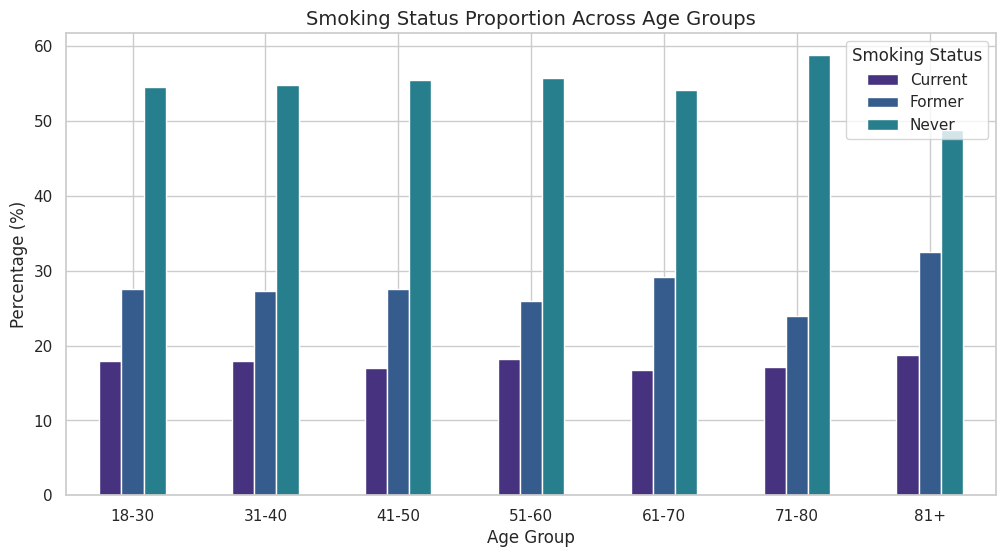

In [18]:
age_smoking_prop.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Smoking Status Proportion Across Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Smoking Status')
plt.show()

**Age and Smoking Status Analysis**

---
The age distribution is relatively consistent across sex and smoking-status categories, with median ages concentrated around the mid-50s and similar interquartile ranges. This suggests that there is no substantial difference in the overall age distribution between never, current, and former smokers.

When examining smoking status across age groups, the 51–60 age group contains the largest number of observations for both males and females. Never smokers constitute the largest group across most age categories, while current smokers generally have the lowest number of observations. Former smokers tend to fall between the two categories.

However, these results are based on absolute counts, which are influenced by the number of observations in each age group. Therefore, the plots do not establish whether age is associated with smoking status. Further analysis using within-age-group proportions would provide a more meaningful assessment of the relationship between age and smoking status.

In [19]:
data.head()

,patient_id,age,sex,resting_bp_systolic,resting_bp_diastolic,cholesterol_total,hdl,ldl,triglycerides,fasting_blood_sugar,hba1c,bmi,resting_heart_rate,max_heart_rate_achieved,chest_pain_type,exercise_induced_angina,st_depression,family_history,smoker_status,alcohol_units_per_week,exercise_minutes_per_week,sleep_hours,stress_score,wearable_owner,daily_steps,diet_quality_score,has_heart_disease,age_group
0,1,44,Male,117,74,193,57,106,119,112,5.20,26.50,74,165,Asymptomatic,False,0.30,False,Never,2.90,86,5.40,19.80,True,7731,62.90,0,41-50
1,2,57,Male,139,94,185,69,110,35,114,5.90,20.80,63,150,Non-Anginal Pain,False,2.10,False,Never,3.00,132,4.30,45.80,True,2629,74.60,1,51-60
2,3,29,Male,128,78,197,52,108,157,95,5.50,24.50,81,210,Asymptomatic,False,0.80,False,Current,3.50,128,5.10,17.70,True,9290,65.70,0,18-30
3,4,72,Male,132,86,197,59,104,143,92,4.80,27.30,93,137,Asymptomatic,False,2.10,False,Never,2.70,18,6.80,63.60,True,7373,48.50,1,71-80
4,5,62,Female,116,75,154,65,75,104,135,6.20,26.00,86,181,Atypical Angina,True,1.30,True,Former,3.30,24,8.20,58.70,False,6331,47.30,1,61-70


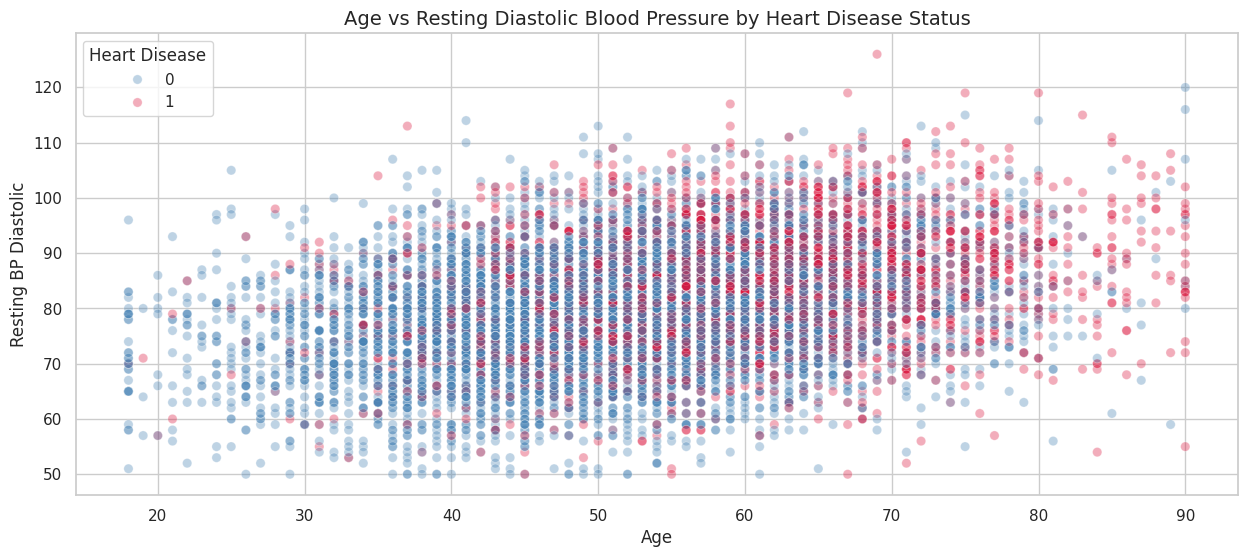

In [20]:
plt.figure(figsize=(15, 6))

sns.scatterplot(
    data=data,
    x='age',
    y='resting_bp_diastolic',
    hue='has_heart_disease',
    palette={0: 'steelblue', 1: 'crimson'},
    alpha=0.35,
    s=45
)

plt.title('Age vs Resting Diastolic Blood Pressure by Heart Disease Status')
plt.xlabel('Age')
plt.ylabel('Resting BP Diastolic')
plt.legend(title='Heart Disease')

plt.show()

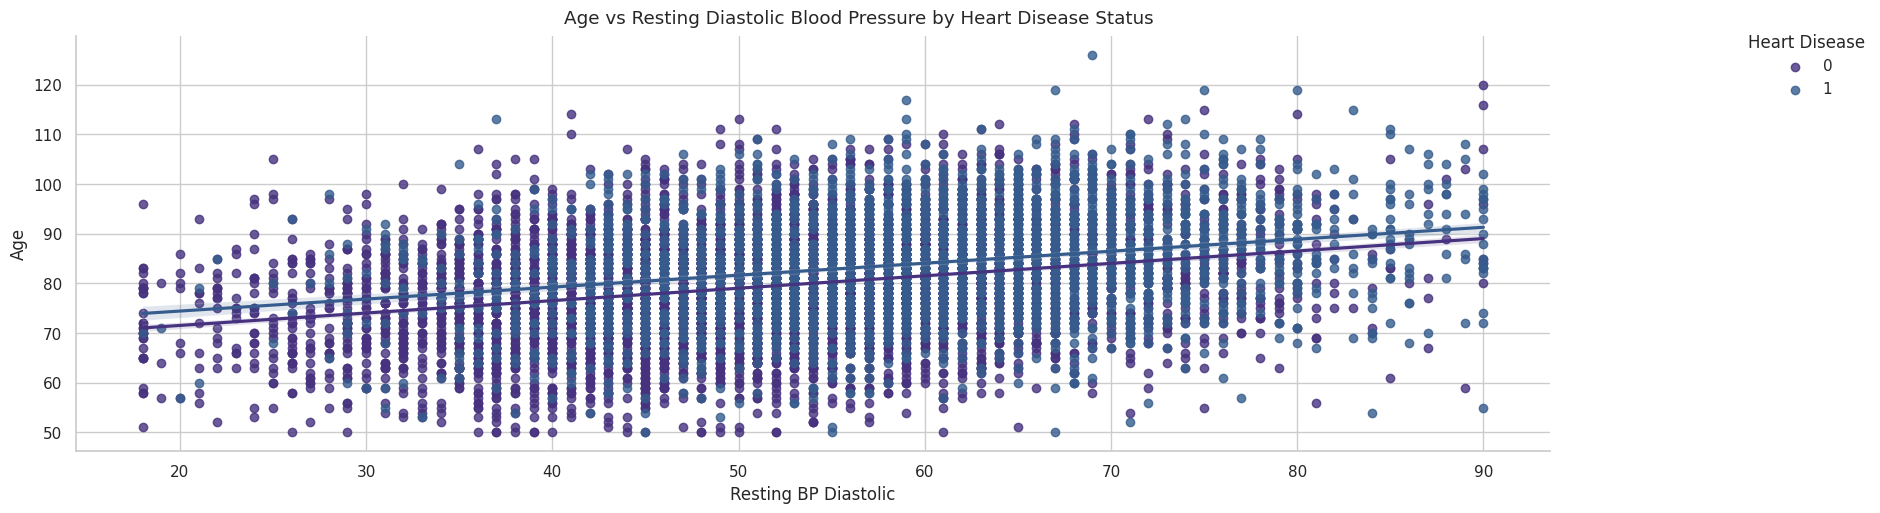

In [21]:
g = sns.lmplot(
    x="age",
    y="resting_bp_diastolic",
    hue="has_heart_disease",
    data=data,
    height=5,
    aspect=19/6,
    legend=True
)
g.set_axis_labels("Resting BP Diastolic", "Age")
g.fig.suptitle('Age vs Resting Diastolic Blood Pressure by Heart Disease Status', y=1.02)
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1), title='Heart Disease')
plt.show()

---
Resting diastolic blood pressure shows a weak positive relationship with age, with values tending to increase and spread more widely in older individuals. Heart disease cases (shown in red) appear more concentrated among older individuals with higher diastolic blood pressure, suggesting these two factors may be associated with elevated heart disease risk, though the overlap between disease and non-disease groups across all ages indicates this relationship is not strongly deterministic.

In [22]:
corr = data['resting_bp_diastolic'].corr(data['age'])
print(f"Correlation: {corr:.3f}")

Correlation: 0.325


---
Resting diastolic blood pressure shows a weak-to-moderate positive correlation with age (r = 0.325), indicating that blood pressure tends to rise somewhat with age, though the relationship is far from strong — a wide spread of values exists at every age. Heart disease cases appear more concentrated among older individuals with higher diastolic blood pressure, suggesting these factors may be jointly associated with elevated risk, though considerable overlap between disease and non-disease groups across the age range indicates the relationship is not strongly deterministic.

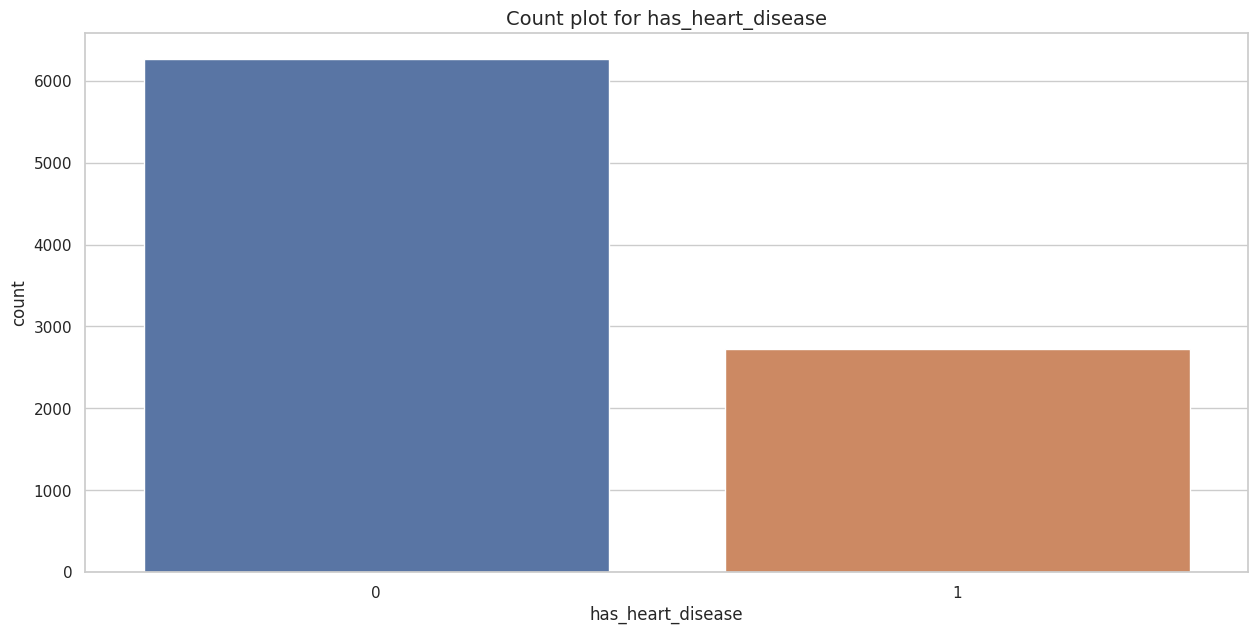

In [23]:
# ============================================================
# Checking for imbalance in the dataset.
# ============================================================
plt.figure(figsize=(15,7))
sns.countplot(data=data,x = 'has_heart_disease', palette='deep')
plt.title('Count plot for has_heart_disease')
plt.show()

# **4. Data Preparation for ML.**

In [24]:
data.head()

,patient_id,age,sex,resting_bp_systolic,resting_bp_diastolic,cholesterol_total,hdl,ldl,triglycerides,fasting_blood_sugar,hba1c,bmi,resting_heart_rate,max_heart_rate_achieved,chest_pain_type,exercise_induced_angina,st_depression,family_history,smoker_status,alcohol_units_per_week,exercise_minutes_per_week,sleep_hours,stress_score,wearable_owner,daily_steps,diet_quality_score,has_heart_disease,age_group
0,1,44,Male,117,74,193,57,106,119,112,5.20,26.50,74,165,Asymptomatic,False,0.30,False,Never,2.90,86,5.40,19.80,True,7731,62.90,0,41-50
1,2,57,Male,139,94,185,69,110,35,114,5.90,20.80,63,150,Non-Anginal Pain,False,2.10,False,Never,3.00,132,4.30,45.80,True,2629,74.60,1,51-60
2,3,29,Male,128,78,197,52,108,157,95,5.50,24.50,81,210,Asymptomatic,False,0.80,False,Current,3.50,128,5.10,17.70,True,9290,65.70,0,18-30
3,4,72,Male,132,86,197,59,104,143,92,4.80,27.30,93,137,Asymptomatic,False,2.10,False,Never,2.70,18,6.80,63.60,True,7373,48.50,1,71-80
4,5,62,Female,116,75,154,65,75,104,135,6.20,26.00,86,181,Atypical Angina,True,1.30,True,Former,3.30,24,8.20,58.70,False,6331,47.30,1,61-70


In [25]:
# ==============================================================
# Spliting the data.
# ===============================================================
X = data.drop(columns=[
    'has_heart_disease',
    'age_group',
    'patient_id'
])
y = data['has_heart_disease']

num_col = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

cat_col = X.select_dtypes(include=['object', 'category']).columns.tolist()

# ---------------------Splitting into traing and testing set---------------
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42,test_size=0.2)
print(f"X_train: {X_train.shape},y_train:{y_train.shape}")

X_train: (7200, 25),y_train:(7200,)


In [26]:
# ------------Creating A pipeline for data prepearing-----------
for col in cat_col:
    uni = data[col].unique()
    print(uni)

['Male' 'Female']
['Asymptomatic' 'Non-Anginal Pain' 'Atypical Angina' 'Typical Angina']
['Never' 'Current' 'Former']


---
Since all the categorical features in our dataset are nominal and do not have a meaningful natural order, we will use OneHotEncoder to transform them into numerical features.

In [27]:
# ==========================================================================
# Creating a full pipeline
# ==========================================================================
num_transform = Pipeline(steps=[
    ('scale', StandardScaler())
])

cat_transform = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', num_transform, num_col),
        ('categorical', cat_transform, cat_col)
    ]
)



# **5. Model Selection**

In [28]:
# ===========================================================================
# Doing the hyperparameter tuning.
# ===========================================================================

#--------------------------- 1. Models to compare ------------------
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    ))
])

In [29]:
#----------------------------- 2. Define parameter grids ----------------------

#========For LogisticTegrassion===========
param_grid_lr = {
    'model__C': [0.02, 0.05, 1, 10],
    'model__solver': ['liblinear', 'lbfgs']
}

#===========For SVM =======================
param_grid_svm = {
    'model__C': [0.05, 1, 10],
    'model__kernel': ['linear', 'rbf'],
    'model__gamma': ['scale', 'auto']
}

# ========= For random Forest ===============
param_grid_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 10, 15],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2],
    'model__max_features': ['sqrt']
}

# ========== For GradientBoosting ===========
param_grid_gb = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3],
    'model__min_samples_split': [2, 5]
}

In [30]:

# =========================================================================
# cross validation using StratifiedKFold
# =========================================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# 3. CROSS_VALIDATE (Comprehensive tracking of multiple metrics and time)
# Use case: Advanced reporting and detecting overfitting.
metrics = ["accuracy", "precision", "recall",'f1','roc_auc']
cv_results = cross_validate(
    full_pipeline, 
    X_train, 
    y_train, 
    cv=cv, 
    scoring=metrics, 
    return_train_score=True,
    n_jobs=-1
)

for metric in metrics:
    test_scores = cv_results[f'test_{metric}']
    train_scores = cv_results[f'train_{metric}']

    print(
        f"{metric:10} ",
        f"Train: {train_scores.mean():.4f} ",
        f"Test: {test_scores.mean():.4f} ± {test_scores.std():.4f}"
        )

accuracy    Train: 0.9492  Test: 0.8503 ± 0.0050
precision   Train: 0.8922  Test: 0.7326 ± 0.0123
recall      Train: 0.9459  Test: 0.7936 ± 0.0146
f1          Train: 0.9182  Test: 0.7617 ± 0.0070
roc_auc     Train: 0.9902  Test: 0.9189 ± 0.0042


In [31]:
# ==============================================================================
# ========== 5. Build a function for the searc ==================
#==============================================================================

def run_grid_search(model, param_grid, name):

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    print(f"\n{'='*60}")
    print(f"{name}")
    print(f"{'='*60}")
    print(f"Best ROC-AUC: {grid.best_score_:.4f}")
    print(f"Best Parameters:")
    print(grid.best_params_)

    return grid

In [32]:
# ================================================================
# ========================== 6. Run the searches =================
# ================================================================
results = {}

results['Logistic Regression'] = run_grid_search(
    models['Logistic Regression'],
    param_grid_lr,
    'Logistic Regression'
)

results['SVM'] = run_grid_search(
    models['SVM'],
    param_grid_svm,
    'SVM'
)

results['Random Forest'] = run_grid_search(
    models['Random Forest'],
    param_grid_rf,
    'Random Forest'
)

results['Gradient Boosting'] = run_grid_search(
    models['Gradient Boosting'],
    param_grid_gb,
    'Gradient Boosting'
)


Fitting 5 folds for each of 8 candidates, totalling 40 fits

Logistic Regression
Best ROC-AUC: 0.9364
Best Parameters:
{'model__C': 0.05, 'model__solver': 'liblinear'}
Fitting 5 folds for each of 12 candidates, totalling 60 fits

SVM
Best ROC-AUC: 0.9362
Best Parameters:
{'model__C': 0.05, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Random Forest
Best ROC-AUC: 0.9205
Best Parameters:
{'model__max_depth': 15, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Fitting 5 folds for each of 16 candidates, totalling 80 fits

Gradient Boosting
Best ROC-AUC: 0.9311
Best Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}


In [33]:
# =============================================================
# ================ 7. Compare the models ======================
# ==============================================================
for name, grid in results.items():
    print(
        f"{name:20} ",
        f"ROC-AUC: {grid.best_score_:.4f}"
    )


Logistic Regression   ROC-AUC: 0.9364
SVM                   ROC-AUC: 0.9362
Random Forest         ROC-AUC: 0.9205
Gradient Boosting     ROC-AUC: 0.9311


In [34]:
# =================================================================
# Selecting the best model found by grid search (by ROC-AUC)
# =================================================================
best_model_name = max(results, key=lambda name: results[name].best_score_)
best_pipeline = results[best_model_name].best_estimator_
 
print(f"\nBest model overall: {best_model_name} "
      f"(CV ROC-AUC: {results[best_model_name].best_score_:.4f})")


Best model overall: Logistic Regression (CV ROC-AUC: 0.9364)


In [35]:
# ============================================
# Fitting the model
# ===============================================
# best_pipeline was already fit on X_train/y_train inside GridSearchCV
# (refit=True by default), so this call is redundant but kept explicit
# in case scoring/refit settings change later.
best_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'resting_bp_systolic',
                                                   'resting_bp_diastolic',
                                                   'cholesterol_total', 'hdl',
                                                   'ldl', 'triglycerides',
                                                   'fasting_blood_sugar',
                                                   'hba1c', 'bmi',
                                                   'resting_heart_rate',
                                                   'max_heart_rate_achieved',
                                                   'st_depression',
                                                   'alcohol_units_per_week',
                                                   'exercise_minutes_per_week',
                                                   'sleep_hours',
                                                   'stress_score',
                                                   'daily_steps',
                                                   'diet_quality_score']),
                                                 ('categorical',
                                                  Pipeline(steps=[('encode',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'chest_pain_type',
                                                   'smoker_status'])])),
                ('smote', SMOTE(random_state=42)),
                ('model',
                 LogisticRegression(C=0.05, max_iter=1000, random_state=42,
                                    solver='liblinear'))])

In [36]:
# ============================================
# Making prediction on untouched test set
# ===============================================
y_predict = best_pipeline.predict(X_test)

In [37]:
# ==============================================================
# Printing the Evaluation metrices
# ==============================================================
print("Accuracy :", accuracy_score(y_test, y_predict))
print("Precision:", precision_score(y_test, y_predict))
print("Recall   :", recall_score(y_test, y_predict))
print("F1       :", f1_score(y_test, y_predict))
 
print("\nClassification Report:")
print(classification_report(y_test, y_predict))

Accuracy : 0.8655555555555555
Precision: 0.74079754601227
Recall   : 0.8687050359712231
F1       : 0.7996688741721855

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.86      0.90      1244
           1       0.74      0.87      0.80       556

    accuracy                           0.87      1800
   macro avg       0.84      0.87      0.85      1800
weighted avg       0.88      0.87      0.87      1800



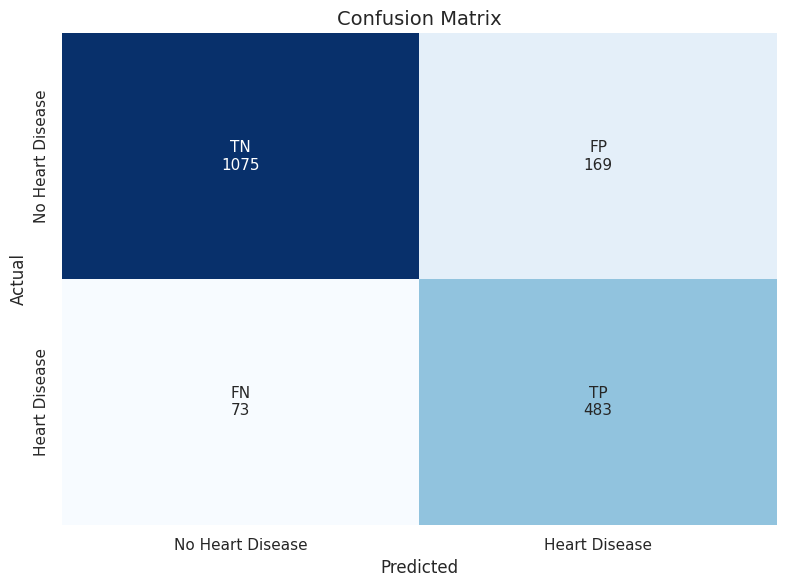

In [38]:

# ===============================================================
# Visualizing the Confusion Matrix
# Confusion Matrix with TN, FP, FN, TP
# ===============================================================
conf_matrix = confusion_matrix(y_test,y_predict)

tn, fp, fn, tp = conf_matrix.ravel()

labels = [
    [f'TN\n{tn}', f'FP\n{fp}'],
    [f'FN\n{fn}', f'TP\n{tp}']
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    conf_matrix,
    annot=labels,
    fmt='',
    cmap='Blues',
    xticklabels=['No Heart Disease', 'Heart Disease'],
    yticklabels=['No Heart Disease', 'Heart Disease'],
    cbar=False
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [39]:
# ===================================================================
# Calculating the ROC-AUC
# ===================================================================

y_probability = best_pipeline.predict_proba(X_test)[:, 1]

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_probability)
)

ROC-AUC: 0.9419139929214184


In [40]:
# === Calculating the ROC curve
fpr,tpr,thresholds = roc_curve(y_test,y_probability)

# === Calculating the ROC=AUC 
roc_auc = roc_auc_score(y_test,y_probability)

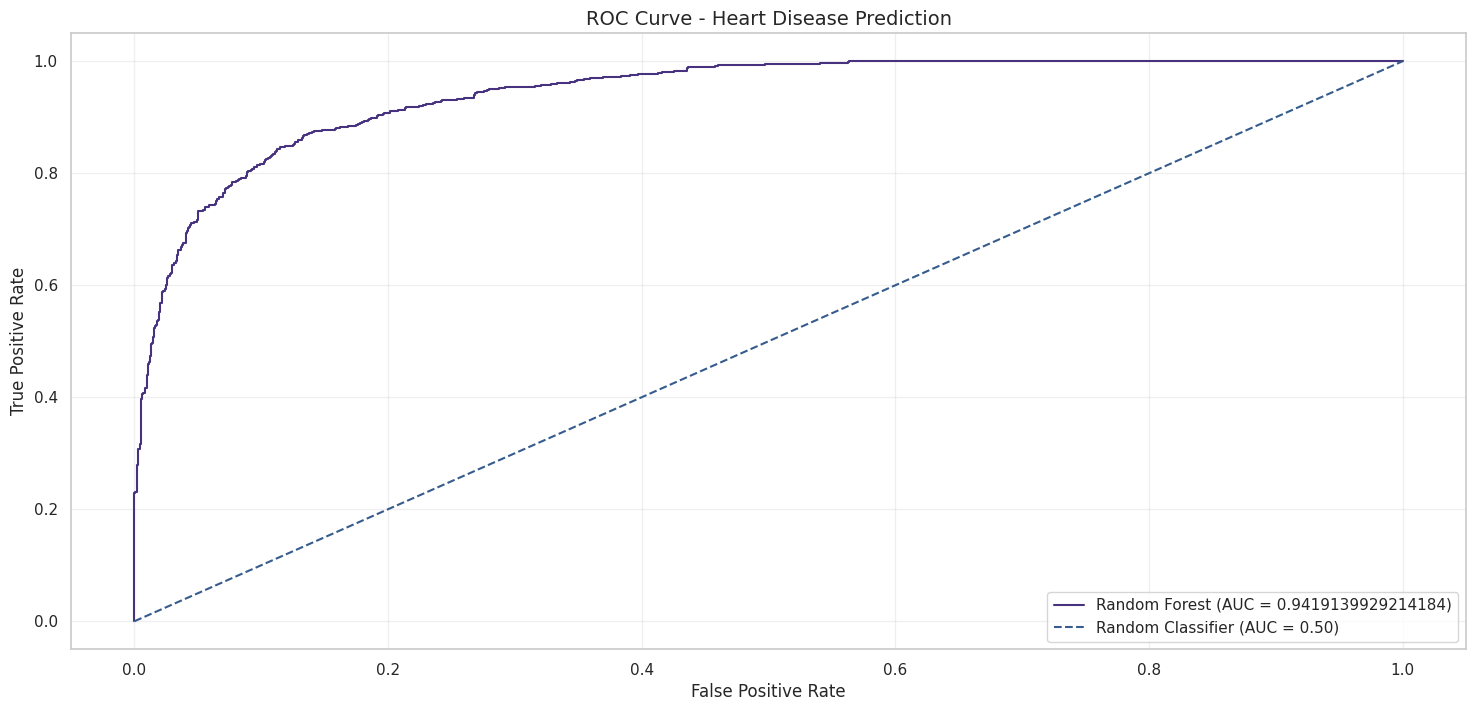

In [41]:
# ================================================================
# Creating a plot for the ROC-AUC
# ================================================================
plt.figure(figsize=(18,8))
plt.plot(
    fpr,
    tpr,
    label=f'Random Forest (AUC = {roc_auc})'
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier (AUC = 0.50)'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Heart Disease Prediction')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.show()